# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

**Name:** Spoorthi A N  |  **SRN:** PES2UG24CS515

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 8 / 8 / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
frame_bytes = 1920 * 1080 * 3
fleet_tb = frame_bytes * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3) * (10 * 24 * 3600) * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

Spatially, dropping to 640 x 360 keeps only 11% of the pixels per frame, so fine detail is gone for good: a face or a license plate becomes a handful of pixels that no raster interpolation can sharpen back (Slides 13, 36). Temporally, dropping to 10 fps loses fast motion: between two frames a quick movement (a swinging arm, a thrown object) travels so far that the correspondence problem can no longer match it, so its direction and speed are lost forever (Slide 37).

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

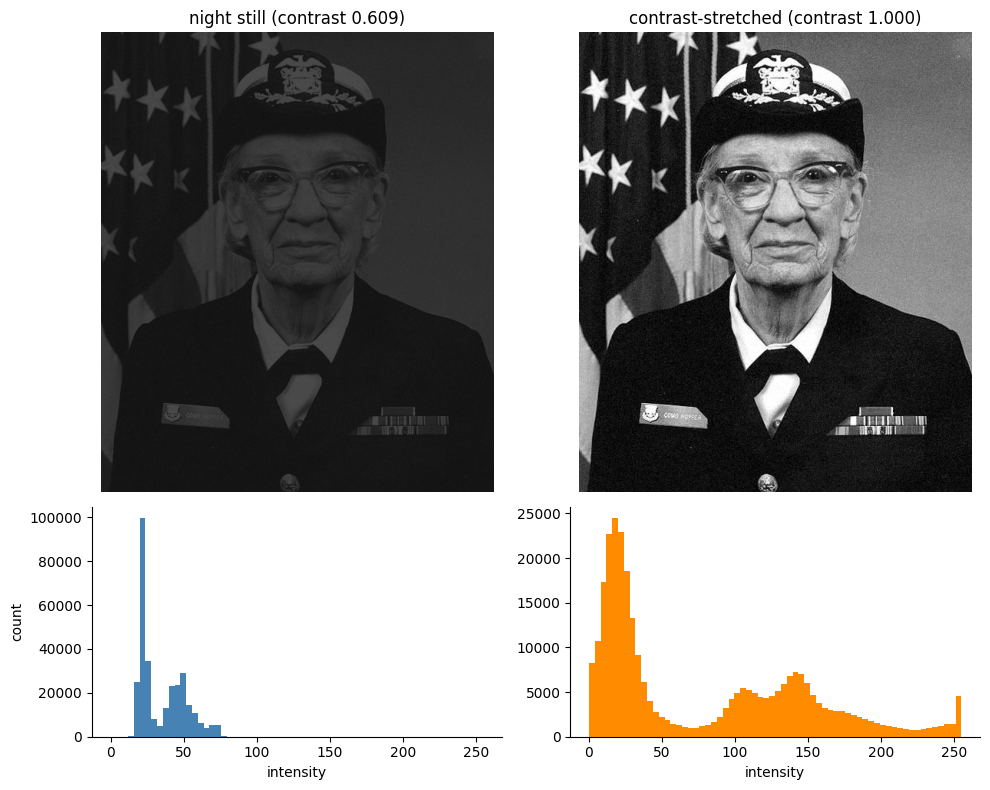

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title(f"night still (contrast {c_before:.3f})")
axes[0, 0].axis("off")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title(f"contrast-stretched (contrast {c_after:.3f})")
axes[0, 1].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="steelblue")
axes[1, 0].set_xlabel("intensity"); axes[1, 0].set_ylabel("count")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="darkorange")
axes[1, 1].set_xlabel("intensity")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night histogram is a narrow, roughly single hump squeezed into the dark end of the range - in the Slide 18 vocabulary, a low-key, low-contrast distribution that uses only a small part of 0-255. Stretching made the image readable without adding information because the sensor had already captured those small intensity differences; the stretch simply remapped the occupied range onto the full display range so our eyes could see them. A histogram alone can never say what is in the picture, because it only counts intensities and forgets where they are: completely different images can share the same histogram ("Same Histogram != Same Image").

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (speed < 3 px/s): 69-78 s
Running  (speed > 25 px/s): 79-86 s
Audio event: first frame above -20 dB is frame 2250 (t = 75.0 s)
Lighting event: brightness jump > 40 at frame 3000 (t = 100.0 s)


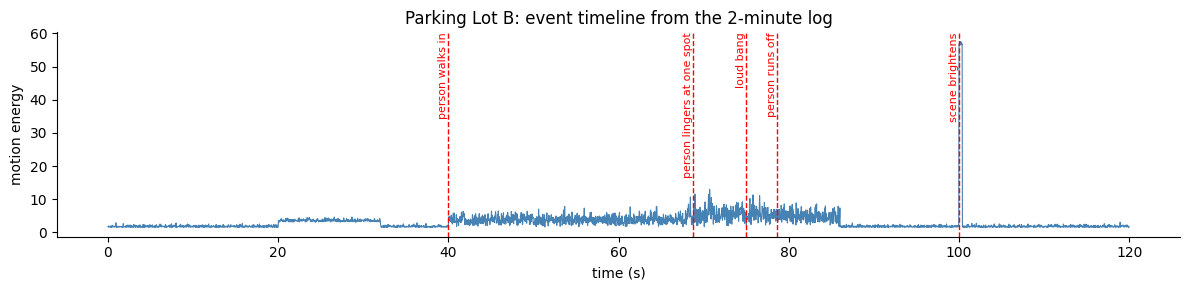

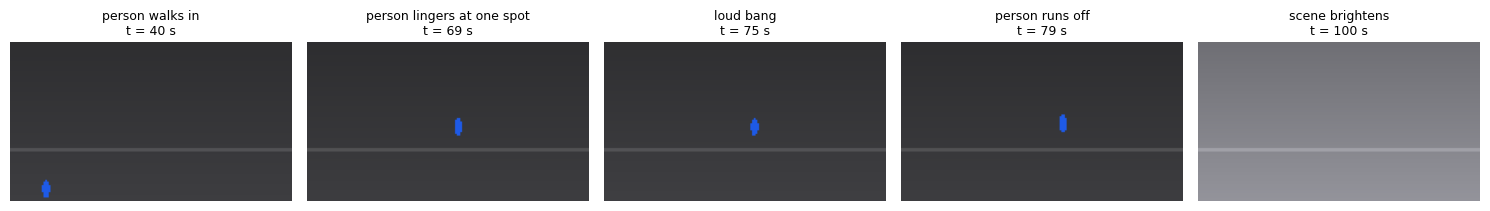

In [4]:
# TODO 1: person speed (px/s)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))
speed_s = speed.rolling(FPS, center=True).median()   # smooth single-frame tracking jitter

# TODO 2: standing / running time ranges (print the first and last time of each)
def time_ranges(mask):
    mask = mask.fillna(False).to_numpy()
    edges = np.diff(mask.astype(int))
    starts = list(np.where(edges == 1)[0] + 1)
    ends = list(np.where(edges == -1)[0])
    if mask[0]: starts = [0] + starts
    if mask[-1]: ends = ends + [len(mask) - 1]
    return [(cctv.time_s.iloc[s], cctv.time_s.iloc[e]) for s, e in zip(starts, ends)]

standing_ranges = [(a, b) for a, b in time_ranges(speed_s < 3) if b - a >= 2]
running_ranges = [(a, b) for a, b in time_ranges(speed_s > 25) if b - a >= 1]
print("Standing (speed < 3 px/s):", ", ".join(f"{a:.0f}-{b:.0f} s" for a, b in standing_ranges))
print("Running  (speed > 25 px/s):", ", ".join(f"{a:.0f}-{b:.0f} s" for a, b in running_ranges))

# TODO 3: event frame indices
audio_event_idx = cctv.index[cctv.audio_level_db > -20][0]
lighting_event_idx = cctv.index[cctv.mean_brightness.diff() > 40][0]
print(f"Audio event: first frame above -20 dB is frame {audio_event_idx} (t = {cctv.time_s[audio_event_idx]:.1f} s)")
print(f"Lighting event: brightness jump > 40 at frame {lighting_event_idx} (t = {cctv.time_s[lighting_event_idx]:.1f} s)")

# TODO 4: annotated motion-energy timeline
person_in = cctv.time_s[cctv.person_x.notna()].min()
events = [(person_in, "person walks in")]
if standing_ranges:
    events.append((standing_ranges[0][0], "person lingers at one spot"))
events.append((cctv.time_s[audio_event_idx], "loud bang"))
if running_ranges:
    events.append((running_ranges[0][0], "person runs off"))
events.append((cctv.time_s[lighting_event_idx], "scene brightens"))
events.sort()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, color="steelblue")
ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy")
ax.set_title("Parking Lot B: event timeline from the 2-minute log")
for t_ev, lab in events:
    ax.axvline(t_ev, color="red", ls="--", lw=1)
    ax.annotate(lab, (t_ev, ax.get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=8, color="red")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(15, 3))
for ax_k, (t_ev, lab) in zip(axes, events):
    i = (cctv.time_s - t_ev).abs().idxmin()
    ax_k.imshow(render_frame(cctv.iloc[i]))
    ax_k.set_title(f"{lab}\nt = {cctv.time_s[i]:.0f} s", fontsize=9)
    ax_k.axis("off")
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes every 20 s would most likely miss the two moments that matter: the bang at exactly 75 s (between the 60 s and 80 s samples) and the person's suspicious 69-78 s standstill - the reviewer would see someone walking, then someone running, with no frame of what happened in between. The approach used here is content-based keyframe selection (Slide 40): keyframes are chosen where the content actually changes (motion spikes, audio events, brightness jumps) instead of on a fixed clock.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

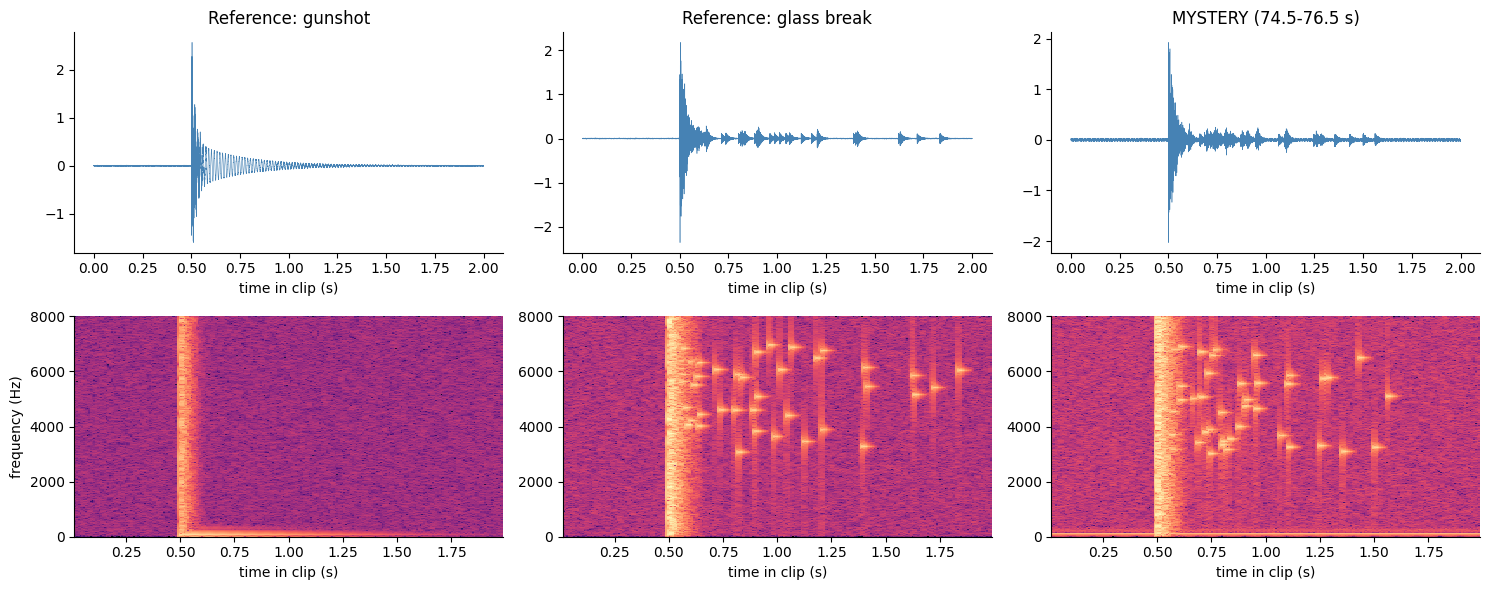

{'Reference: gunshot': 0.0035787582932560106, 'Reference: glass break': 0.989974198075193, 'MYSTERY (74.5-76.5 s)': 0.8782341703965806}
Verdict: the 75 s bang was BREAKING GLASS - its high-frequency energy share (0.88) sits far closer to the glass break reference than to the other.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for j, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    axes[0, j].plot(t_clip, clip, lw=0.4, color="steelblue")
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("time in clip (s)")
    f, ts, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    axes[1, j].pcolormesh(ts, f, 10 * np.log10(Sxx + 1e-14), shading="auto", cmap="magma")
    axes[1, j].set_ylim(0, 8000)
    if j == 0: axes[1, j].set_ylabel("frequency (Hz)")
    axes[1, j].set_xlabel("time in clip (s)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    seg = clip[int(0.7 * FS): int(1.7 * FS)]
    f, Pxx = signal.welch(seg, fs=FS, nperseg=2048)
    hf_fraction[name] = float(Pxx[f > 3000].sum() / Pxx.sum())

print(hf_fraction)
# TODO 4: verdict
m = hf_fraction["MYSTERY (74.5-76.5 s)"]
d_gun = abs(m - hf_fraction["Reference: gunshot"])
d_glass = abs(m - hf_fraction["Reference: glass break"])
verdict = "BREAKING GLASS" if d_glass < d_gun else "GUNSHOT"
match = "glass break" if d_glass < d_gun else "gunshot"
print(f"Verdict: the 75 s bang was {verdict} - its high-frequency energy share ({m:.2f}) sits far closer to the {match} reference than to the other.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No - from the waveforms alone I could not separate them with confidence: both are a loud burst at 0.5 s that decays afterwards, and the amplitude envelope looks similar. The spectrogram adds the three dimensions time, frequency and magnitude (Slide 57), showing where the energy lives in frequency as time passes. The decider was the pattern of scattered high-frequency specks - the lingering glass tinkle above 3 kHz - in the mystery clip, which matches the glass reference, while the gunshot is a sharp vertical stripe with a low-frequency boom and silence after.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

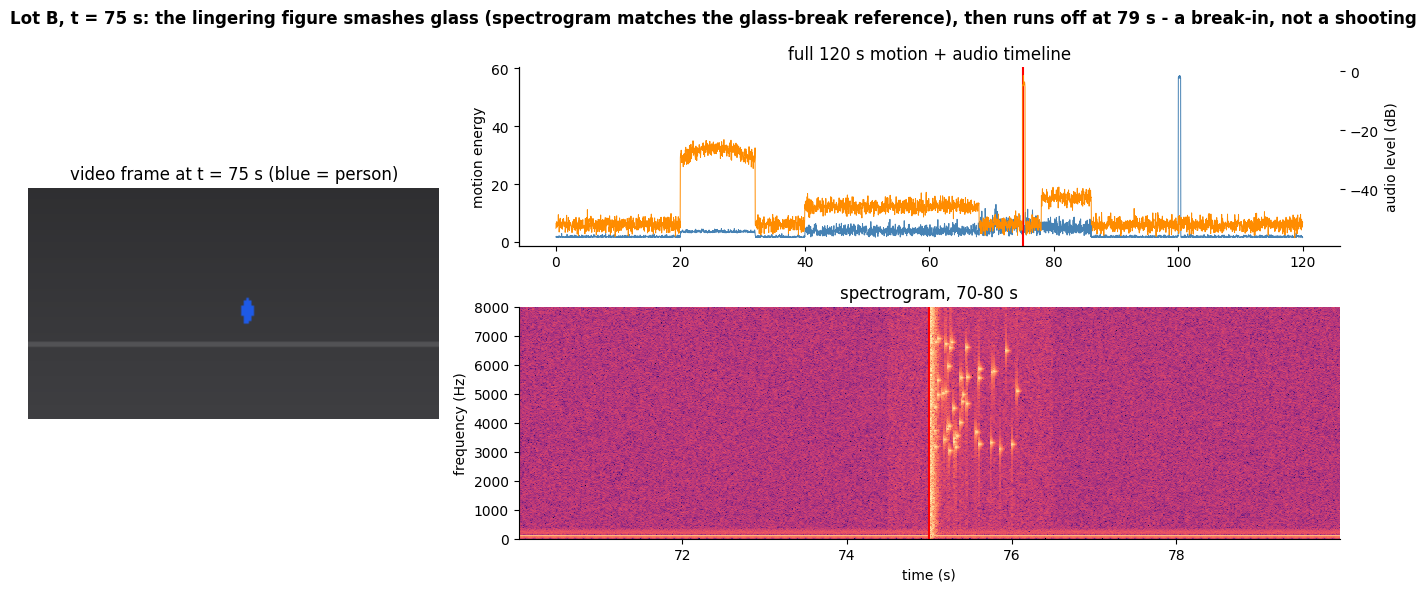

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = (cctv.time_s - t_sel).abs().idxmin()
ax_f = fig.add_subplot(gs[:, 0])
ax_f.imshow(render_frame(cctv.iloc[i_sel]))
ax_f.set_title(f"video frame at t = {cctv.time_s[i_sel]:.0f} s (blue = person)")
ax_f.axis("off")

ax_t = fig.add_subplot(gs[0, 1])
ax_t.plot(cctv.time_s, cctv.motion_energy, lw=0.7, color="steelblue", label="motion energy")
ax_t.set_ylabel("motion energy")
ax_a = ax_t.twinx()
ax_a.plot(cctv.time_s, cctv.audio_level_db, lw=0.7, color="darkorange", label="audio level (dB)")
ax_a.set_ylabel("audio level (dB)")
ax_t.axvline(t_sel, color="red", lw=1.5)
ax_t.set_title("full 120 s motion + audio timeline")

ax_s = fig.add_subplot(gs[1, 1])
sel = (t_audio >= 70) & (t_audio < 80)
f, ts, Sxx = signal.spectrogram(x_audio[sel], fs=FS, nperseg=512, noverlap=384)
ax_s.pcolormesh(ts + 70, f, 10 * np.log10(Sxx + 1e-14), shading="auto", cmap="magma")
ax_s.set_ylim(0, 8000)
ax_s.axvline(t_sel, color="red", lw=1.5)
ax_s.set_xlabel("time (s)"); ax_s.set_ylabel("frequency (Hz)")
ax_s.set_title("spectrogram, 70-80 s")

fig.suptitle("Lot B, t = 75 s: the lingering figure smashes glass (spectrogram matches the glass-break reference), then runs off at 79 s - a break-in, not a shooting",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

With a +2 s audio offset the bang would appear at about 73 s in the spectrogram while the frame and the timeline marker show the flash at 75 s, so the briefing would claim the sound came two seconds before the visible event - possibly blaming the wrong moment or person. The spectrogram panel makes the mistake visible: the red 75 s marker no longer lines up with the bang's bright vertical stripe, contradicting the synchronized timeline above it.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

A car drove through Lot B at 20-32 s, then at about 40 s a person walked in, stood at one spot from roughly 69 to 78 s, and at exactly 75 s the microphone caught a sharp bang whose spectrogram matches the reference glass break (about 88% of its energy above 3 kHz), not a gunshot - so this reads as a smashed window, i.e. vandalism or a break-in, not a shooting. The person then ran off between 79 and 86 s, and at 100 s the whole scene suddenly brightened as the floodlight responded. I would open the briefing with the synchronized one-screen view, because it walks the structure -> pattern -> change -> event -> meaning chain at a glance: the timeline gives the overview, and the frame plus spectrogram back the claim at the same 75 s timestamp, with content-based keyframes giving one picture per event so nobody scrubs two minutes of video. On storage, 400 cameras at 1080p/30 fps would produce about 5,900 TB a day uncompressed, so I recommend full resolution only on a short rolling buffer plus all event clips, and 360p/10 fps for routine footage. The one thing the policy must never sacrifice is the spatial detail around the person and the scene they linger at - once faces and plates are downsampled away, no later enhancement brings them back.